# Task assigning

A small software team has a backlog of tasks for four customers. Each task needs certain skills, and
someone who knows the customer finishes much faster than someone who does not. Critical tasks should
not sit behind minor ones. The question is **who does which task, and in what order**.

In this notebook you will:

1. describe a team and its backlog as Python objects,
2. solve it and read the result as one task queue per person,
3. check the result yourself, including the score, without trusting the solver,
4. change the rules so that critical work comes first and the load evens out,
5. find out which person the team can least afford to lose,
6. spend more search time on a result, one round after another,
7. add new tasks to a plan without disturbing the queues.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from optimaru import task_assigning as ta
from optimaru.task_assigning import constraints as rules
from optimaru.task_assigning.models import TaskAssigningSolutionModel, TaskModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the backlog

All times are **integer minutes** from the start of the plan.

| Object | What it holds |
| --- | --- |
| `TaskType` | a kind of work: base duration and the skills it requires |
| `Customer` | who the work is for |
| `Task` | one task: its type, customer, priority and earliest start |
| `Employee` | one person: skills, and an affinity for each customer |
| `TaskAssigningSolution` | all of the above, and the score once solved |

A task's real duration is its base duration times a multiplier from the person's affinity with the
customer: **HIGH 1, MEDIUM 2, LOW 3, NONE 4**. So the same audit takes one person an hour and another
person four.

The team below is fictional: 8 people, 5 kinds of task, 4 customers and 48 tasks.

In [2]:
CUSTOMERS = ["Alder Foods", "Birch Transit", "Cedar Clinic", "Dune Energy"]
TASK_TYPES = [
    ("BUG", "Bug fix", 45, ["Backend"]),
    ("UI", "Screen change", 40, ["Frontend"]),
    ("MIG", "Data migration", 70, ["Database", "Backend"]),
    ("AUD", "Security audit", 60, ["Security"]),
    ("DEP", "Cloud deployment", 50, ["Cloud"]),
]
SKILLS = {
    "Ana": ["Backend", "Database"], "Ben": ["Backend", "Cloud"], "Cho": ["Frontend"],
    "Dia": ["Frontend", "Backend"], "Eli": ["Security", "Cloud"], "Fay": ["Database", "Backend", "Security"],
    "Gus": ["Cloud", "Frontend"], "Hana": ["Backend", "Security"],
}
AFFINITIES = [ta.Affinity.NONE, ta.Affinity.LOW, ta.Affinity.MEDIUM, ta.Affinity.HIGH]
MULTIPLIER = {ta.Affinity.HIGH: 1, ta.Affinity.MEDIUM: 2, ta.Affinity.LOW: 3, ta.Affinity.NONE: 4}
PRIORITIES = [ta.Priority.MINOR, ta.Priority.MAJOR, ta.Priority.CRITICAL]

rng = np.random.default_rng(3)
BACKLOG = [(int(rng.choice(5, p=[0.35, 0.2, 0.15, 0.15, 0.15])), int(rng.integers(4)),
            PRIORITIES[int(rng.choice(3, p=[0.5, 0.35, 0.15]))]) for _ in range(48)]
AFFINITY = {name: [AFFINITIES[int(a)] for a in rng.choice(4, 4, p=[0.1, 0.3, 0.35, 0.25])] for name in SKILLS}


def make_solution(names=tuple(SKILLS)):
    """A fresh, unassigned backlog. Solvers work in place, so each experiment gets its own."""
    seen = {}
    tasks = []
    for number, (task_type, customer, priority) in enumerate(BACKLOG):
        seen[task_type] = seen.get(task_type, 0) + 1
        tasks.append(ta.Task(f"T{number:02d}", task_type, seen[task_type], customer, 0, priority))
    return ta.TaskAssigningSolution(
        [ta.TaskType(code, title, minutes, skills) for code, title, minutes, skills in TASK_TYPES],
        [ta.Customer(str(i), name) for i, name in enumerate(CUSTOMERS)],
        tasks,
        [ta.Employee(name, name, SKILLS[name], AFFINITY[name]) for name in names],
    )


backlog = make_solution()
print(f"{len(backlog.tasks)} tasks, {len(backlog.employees)} people")
print({p.name: sum(t.priority == p for t in backlog.tasks) for p in PRIORITIES})
print(f"{sum(backlog.task_types[t.task_type].base_duration for t in backlog.tasks) / 60:.1f} hours at base duration")

48 tasks, 8 people
{'MINOR': 24, 'MAJOR': 18, 'CRITICAL': 6}
42.5 hours at base duration


Skills decide who **may** do a task, and affinity decides how **fast** they do it. Migrations need two
skills, and only some people hold both.

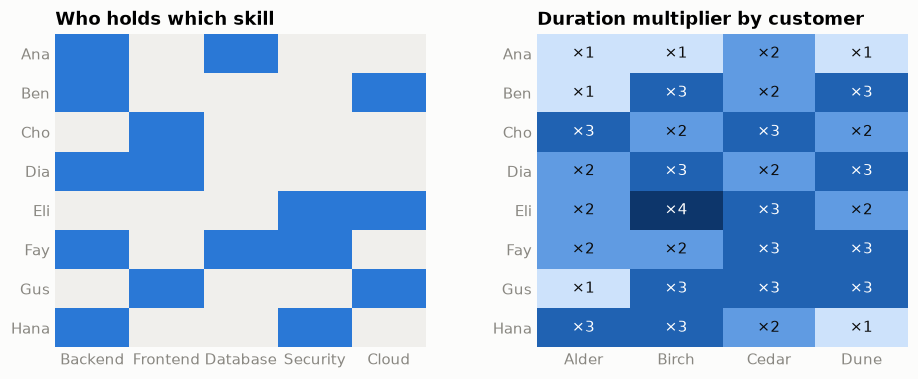

In [3]:
ALL_SKILLS = ["Backend", "Frontend", "Database", "Security", "Cloud"]
names = list(SKILLS)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.7), gridspec_kw={"wspace": 0.3})

has_skill = np.array([[skill in SKILLS[name] for skill in ALL_SKILLS] for name in names], dtype=float)
left.imshow(has_skill, cmap=LinearSegmentedColormap.from_list("skill", ["#f0efec", COLORS[0]]), aspect="auto")
left.set_xticks(range(5), ALL_SKILLS)
left.set_yticks(range(8), names)
left.set_title("Who holds which skill")

multipliers = np.array([[MULTIPLIER[a] for a in AFFINITY[name]] for name in names])
ramp = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
right.imshow(multipliers, cmap=ramp, vmin=1, vmax=4, aspect="auto")
for i, j in np.ndindex(multipliers.shape):
    right.text(j, i, f"×{multipliers[i, j]}", ha="center", va="center",
               color="white" if multipliers[i, j] >= 3 else "#0b0b0b")
right.set_xticks(range(4), [c.split()[0] for c in CUSTOMERS])
right.set_yticks(range(8), names)
right.set_title("Duration multiplier by customer")
for ax in (left, right):
    ax.tick_params(length=0)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
plt.show()

## 2. Solve it

`ta.solve` takes the solution object and works in place, or takes a pydantic model and returns a new
one. The score has four levels, compared in order:

- **hard**: required skills the assigned person lacks. `0` means nobody got a task they cannot do.
- **soft0**: tasks on nobody's list. The search keeps every task assigned, so this stays at `0`.
- **soft1**: minus the sum over people of their finish time squared. The square makes the busiest
  person's last minutes the most expensive ones.
- **soft2**: minus each task's end time, weighted by priority: CRITICAL 4, MAJOR 2, MINOR 1.

Levels are strict: priorities only separate plans that are equal on soft1.

In [4]:
plan = make_solution()
ta.solve(plan, time_limit_seconds=2.0, random_seed=42)


def queue(solution, employee):
    """(task, start, duration, multiplier) for one person, walking the list the way the score does."""
    out, clock = [], 0
    for index in employee.tasks:
        task = solution.tasks[index]
        multiplier = MULTIPLIER[employee.affinity_by_customer[task.customer]]
        start = max(clock, task.min_start_time)
        duration = solution.task_types[task.task_type].base_duration * multiplier
        out.append((task, start, duration, multiplier))
        clock = start + duration
    return out


def finish_times(solution):
    return {e.id: max((start + duration for _, start, duration, _ in queue(solution, e)), default=0)
            for e in solution.employees}


def critical_ends(solution):
    return {task.id: start + duration for e in solution.employees for task, start, duration, _ in queue(solution, e)
            if task.priority == ta.Priority.CRITICAL}


score = plan.score
print("feasible:", score.is_feasible())
print("score   :", score.hard, "/", score.soft0, "/", score.soft1, "/", score.soft2)
print("finish  :", {name: f"{minutes / 60:.1f} h" for name, minutes in finish_times(plan).items()})

feasible: True
score   : 0 / 0 / -2648275 / -21500
finish  : {'Ana': '17.4 h', 'Ben': '6.0 h', 'Cho': '6.7 h', 'Dia': '6.2 h', 'Eli': '7.3 h', 'Fay': '13.0 h', 'Gus': '3.7 h', 'Hana': '8.8 h'}


### One queue per person

Each row is a person working through their list, colored by priority. The label gives the task type
and, for tasks wide enough to carry it, the affinity multiplier: `×1` is a person on their best
customer, and `×3` means the task takes three times its base duration.

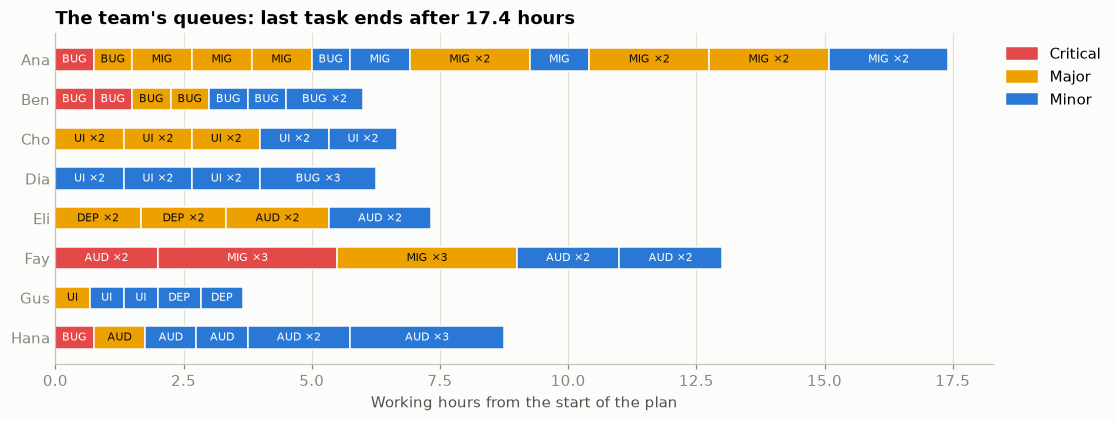

In [5]:
PRIORITY_COLOR = {"CRITICAL": COLORS[7], "MAJOR": COLORS[3], "MINOR": COLORS[0]}
LABEL_COLOR = {"CRITICAL": "white", "MAJOR": "#0b0b0b", "MINOR": "white"}


def draw_queues(ax, solution, new_tasks=()):
    for row, employee in enumerate(solution.employees):
        for task, start, duration, multiplier in queue(solution, employee):
            kind = task.priority.name
            is_new = task.id in new_tasks
            ax.barh(row, duration / 60, left=start / 60, height=0.56, color=PRIORITY_COLOR[kind],
                    edgecolor="#0b0b0b" if is_new else "#fcfcfb", linewidth=2 if is_new else 1, zorder=3 if is_new else 2)
            code = solution.task_types[task.task_type].code
            label = f"{code} ×{multiplier}" if duration >= 75 else code
            ax.text((start + duration / 2) / 60, row, label, ha="center", va="center", fontsize=7.5,
                    color=LABEL_COLOR[kind], zorder=4)
    ax.set_yticks(range(len(solution.employees)), [e.id for e in solution.employees])
    ax.invert_yaxis()
    ax.set(xlabel="Working hours from the start of the plan")
    ax.tick_params(axis="y", length=0)
    ax.grid(True, axis="x")


PRIORITY_LEGEND = [Patch(color=PRIORITY_COLOR[kind], label=kind.capitalize()) for kind in PRIORITY_COLOR]
fig, ax = plt.subplots(figsize=(11, 3.9))
draw_queues(ax, plan)
ax.set_title(f"The team's queues: last task ends after {max(finish_times(plan).values()) / 60:.1f} hours")
ax.legend(handles=PRIORITY_LEGEND, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### How well the work fits the people

Every task above went to someone with the skills, and what varies is how well they know the customer.
This counts each person's tasks by multiplier. The more tasks at `×1`, the less time the team loses.

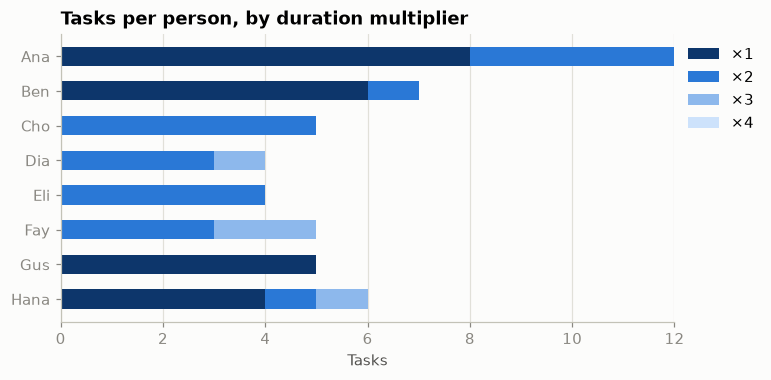

In [6]:
FIT_COLORS = {1: "#0d366b", 2: "#2a78d6", 3: "#8db8ec", 4: "#cde2fb"}
counts = {m: [sum(entry[3] == m for entry in queue(plan, e)) for e in plan.employees] for m in FIT_COLORS}

fig, ax = plt.subplots(figsize=(7.2, 3.4))
left_edge = np.zeros(len(plan.employees))
for multiplier, values in counts.items():
    ax.barh(names, values, left=left_edge, height=0.55, color=FIT_COLORS[multiplier], label=f"×{multiplier}")
    left_edge += values
ax.invert_yaxis()
ax.set(title="Tasks per person, by duration multiplier", xlabel="Tasks")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

The plan is fully described by each person's ordered list. This rebuilds every time from those lists,
counts missing skills, and recomputes all four score levels with no solver code.

In [7]:
PRIORITY_WEIGHT = {ta.Priority.CRITICAL: 4, ta.Priority.MAJOR: 2, ta.Priority.MINOR: 1}


def check_plan(solution):
    missing = soft1 = soft2 = 0
    timing_matches = True
    for employee in solution.employees:
        entries = queue(solution, employee)
        for task, start, duration, _ in entries:
            required = solution.task_types[task.task_type].required_skills
            missing += sum(skill not in employee.skills for skill in required)
            soft2 += PRIORITY_WEIGHT[task.priority] * (start + duration)
            timing_matches &= task.start_time == start
        if entries:
            soft1 += (entries[-1][1] + entries[-1][2]) ** 2
    assigned = sorted(index for employee in solution.employees for index in employee.tasks)
    return {
        "every task on exactly one list": assigned == list(range(len(solution.tasks))),
        "start times match the solver": timing_matches,
        "hard, recomputed": -missing,
        "soft0, recomputed": len(assigned) - len(solution.tasks),
        "soft1, recomputed": -soft1,
        "soft2, recomputed": -soft2,
    }


for label, value in check_plan(plan).items():
    print(f"{label}: {value}")
print(f"solver score: {score.hard} / {score.soft0} / {score.soft1} / {score.soft2}")

every task on exactly one list: True
start times match the solver: True
hard, recomputed: 0
soft0, recomputed: 0
soft1, recomputed: -2648275
soft2, recomputed: -21500
solver score: 0 / 0 / -2648275 / -21500


## 4. Change the rules, not the solver

`list_constraints()` shows what ships with this use case, and `constraints=` takes the list you want.
Only listed constraints are scored.

In [8]:
print(ta.list_constraints())

['no_missing_skills', 'minimize_makespan', 'critical_priority_task_end_time', 'major_priority_task_end_time', 'minor_priority_task_end_time', 'minimize_unassigned_tasks']


### Critical work first

The default weight of 4 only breaks ties among plans with equal soft1, and even then a critical task
trades against several minor ones. Raising the weight makes the end time of critical tasks count for
more within that level, without touching makespan.

Keep the weight moderate. soft2 shares the engine's score with soft1 and only reads correctly while
its size stays below 10^7. Past that it spills into soft1 and the printed levels stop meaning what
this notebook says they mean.

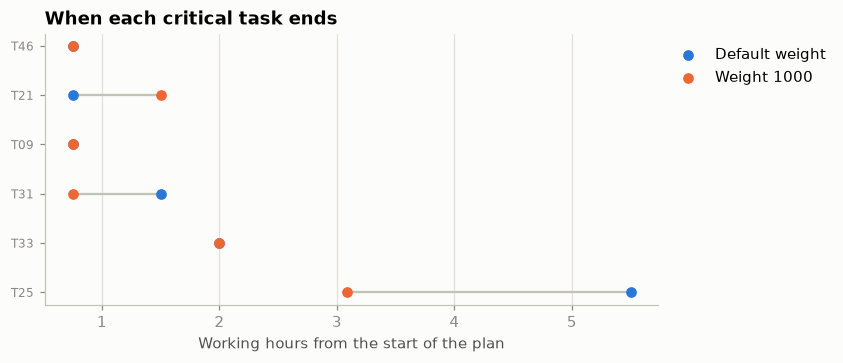

default      critical end: mean 1.9 h, last 5.5 h, soft1 -2648275
weight 1000  critical end: mean 1.5 h, last 3.1 h, soft1 -2648275


In [9]:
def with_rules(makespan=rules.minimize_makespan, critical=rules.critical_priority_task_end_time):
    return rules.get_constraints([
        rules.no_missing_skills, rules.minimize_unassigned_tasks, makespan, critical,
        rules.major_priority_task_end_time, rules.minor_priority_task_end_time,
    ])


SOLVE = {"time_limit_seconds": 2.0, "random_seed": 42}
urgent = make_solution()
ta.solve(urgent, constraints=with_rules(critical=rules.CriticalPriorityTaskEndTime(weight=1000)), **SOLVE)

before, after = critical_ends(plan), critical_ends(urgent)
order = sorted(before, key=before.get)
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for row, task_id in enumerate(order):
    ax.plot([before[task_id] / 60, after[task_id] / 60], [row, row], color="#c3c2b7", linewidth=1.5, zorder=1)
ax.scatter([before[t] / 60 for t in order], range(len(order)), s=36, color=COLORS[0], label="Default weight", zorder=2)
ax.scatter([after[t] / 60 for t in order], range(len(order)), s=36, color=COLORS[1], label="Weight 1000", zorder=2)
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.invert_yaxis()
ax.set(title="When each critical task ends", xlabel="Working hours from the start of the plan")
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, solution, ends in (("default", plan, before), ("weight 1000", urgent, after)):
    print(f"{label:12s} critical end: mean {np.mean(list(ends.values())) / 60:.1f} h, "
          f"last {max(ends.values()) / 60:.1f} h, soft1 {solution.score.soft1}")

### A fairer spread of the load

`minimize_makespan` adds up squared finish times, which can leave one person far behind the others if
that shortens the team's total. `exponent=2` raises that term to the fourth power of the finish
time, so the longest day dominates.

With shaping the printed soft levels no longer read as squared minutes, so compare what the plans do
rather than their scores.

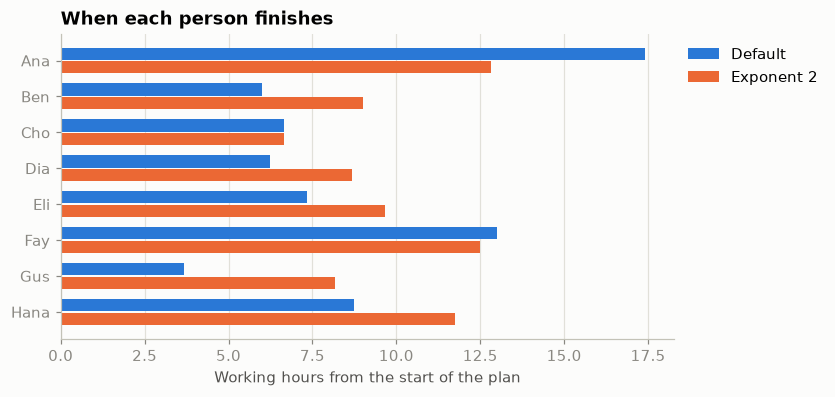

default     busiest 17.4 h, total 69.1 person-hours
exponent 2  busiest 12.8 h, total 79.2 person-hours


In [10]:
even = make_solution()
ta.solve(even, constraints=with_rules(makespan=rules.MinimizeMakespan(weight=1, exponent=2)), **SOLVE)

default_finish, even_finish = finish_times(plan), finish_times(even)
y = np.arange(len(names))
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.barh(y - 0.19, [default_finish[n] / 60 for n in names], height=0.34, color=COLORS[0], label="Default")
ax.barh(y + 0.19, [even_finish[n] / 60 for n in names], height=0.34, color=COLORS[1], label="Exponent 2")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set(title="When each person finishes", xlabel="Working hours from the start of the plan")
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, finish in (("default", default_finish), ("exponent 2", even_finish)):
    print(f"{label:11s} busiest {max(finish.values()) / 60:.1f} h, total {sum(finish.values()) / 60:.1f} person-hours")

## 5. Who can the team least afford to lose?

Remove one person at a time and solve again. This asks more than "how much capacity did we lose": a
person may hold a skill few others have, or be the fast option for a customer. The solver still places
every task, so a skill nobody holds shows up as a negative hard score rather than an empty slot.

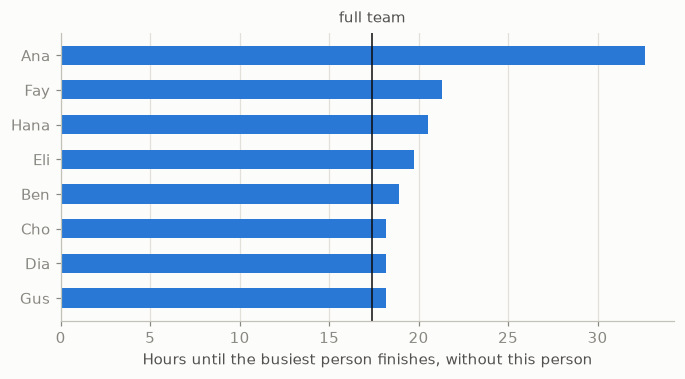

hard score without each person: {'Ana': 0, 'Fay': 0, 'Hana': 0, 'Eli': 0, 'Ben': 0, 'Cho': 0, 'Dia': 0, 'Gus': 0}
without all security people: hard -10, soft0 0, 10 audits still on someone's list


In [11]:
without = {}
for name in names:
    remaining = make_solution([n for n in names if n != name])
    ta.solve(remaining, time_limit_seconds=0.4, random_seed=42)
    without[name] = (max(finish_times(remaining).values()) / 60, remaining.score.hard)

ranked = sorted(names, key=lambda name: -without[name][0])
baseline = max(default_finish.values()) / 60
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.barh(ranked, [without[name][0] for name in ranked], height=0.55, color=COLORS[0])
ax.axvline(baseline, color="#0b0b0b", linewidth=1)
ax.text(baseline, -0.95, "full team", ha="center", color=INK)
ax.invert_yaxis()
ax.set(xlabel="Hours until the busiest person finishes, without this person")
ax.grid(True, axis="x")
plt.show()

print("hard score without each person:", {name: without[name][1] for name in ranked})

no_security = [name for name in names if "Security" not in SKILLS[name]]
remaining = make_solution(no_security)
ta.solve(remaining, time_limit_seconds=0.4, random_seed=42)
audits = sum(t.task_type == 3 for t in remaining.tasks)
print(f"without all security people: hard {remaining.score.hard}, soft0 {remaining.score.soft0}, "
      f"{audits} audits still on someone's list")

## 6. Keep searching from an earlier result

The pydantic models in `optimaru.task_assigning.models` mirror the problem for JSON. `ta.solve` accepts a
model and returns one, and `ta.with_initial_solution` turns an answer into the start of the next search.

Change `random_seed` between rounds. The same start with the same seed repeats the same search, so a
round that finds nothing leaves the next round with the identical input. A step limit makes each round
repeatable, so differences between the lines come from the seeds and the round length. The dotted line
is the best of several fresh solves, which share nothing with the rounds.

A new seed does not rescue rounds that are too short. A line that stops below the dotted line is stuck
on soft1, even if soft2 is still moving underneath it, and the third line shows what longer rounds do.
A line that levels off at the dotted line has nothing obvious left to find.

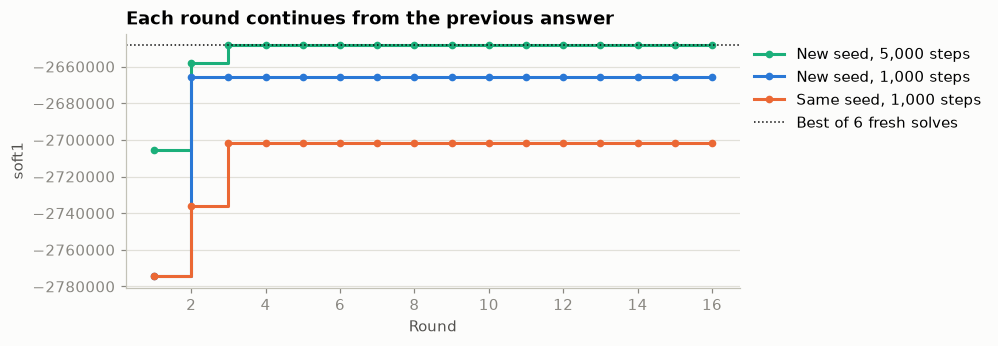

same seed, 1,000: 5 of 15 rounds repeat the previous score, ends at (-2701775, -22210)
new seed, 1,000 : 1 of 15 rounds repeat the previous score, ends at (-2665475, -21555)
new seed, 5,000 : 11 of 15 rounds repeat the previous score, ends at (-2648275, -21500)
6 fresh solves, soft1: -2648275 to -2648275


In [12]:
def run_rounds(rounds, new_seed, steps=1_000):
    problem = TaskAssigningSolutionModel.from_core(make_solution())
    solution, history = None, []
    for round_number in range(rounds):
        config = ta.SolverConfig()
        config.step_count_limit = steps
        start = problem if solution is None else ta.with_initial_solution(problem, solution)
        solution = ta.solve(start, config=config, time_limit_seconds=30.0,
                            random_seed=1 + round_number if new_seed else 1)
        history.append((solution.score_soft1, solution.score_soft2))
    return history


ROUNDS = 16
same_seed, new_seed = run_rounds(ROUNDS, False), run_rounds(ROUNDS, True)
longer = run_rounds(ROUNDS, True, steps=5_000)
fresh_scores = [ta.solve(make_solution(), time_limit_seconds=0.3, random_seed=100 + i).score.soft1 for i in range(6)]

fig, ax = plt.subplots(figsize=(7.2, 3))
for history, color, label in ((longer, COLORS[2], "New seed, 5,000 steps"), (new_seed, COLORS[0], "New seed, 1,000 steps"),
                              (same_seed, COLORS[1], "Same seed, 1,000 steps")):
    ax.plot(range(1, ROUNDS + 1), [score[0] for score in history], color=color, linewidth=2, marker="o",
            markersize=4, drawstyle="steps-post", label=label)
ax.axhline(max(fresh_scores), color="#0b0b0b", linewidth=1, linestyle=":", label="Best of 6 fresh solves")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="soft1")
ax.ticklabel_format(axis="y", style="plain")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, history in (("same seed, 1,000", same_seed), ("new seed, 1,000 ", new_seed), ("new seed, 5,000 ", longer)):
    repeats = sum(a == b for a, b in zip(history, history[1:]))
    print(f"{label}: {repeats} of {ROUNDS - 1} rounds repeat the previous score, ends at {history[-1]}")
print(f"6 fresh solves, soft1: {min(fresh_scores)} to {max(fresh_scores)}")

## 7. New tasks land on a running plan

Two hours in, three urgent tasks arrive. `min_start_time=120` keeps each of them from starting
before that.

This use case has **no pinned field**, so nothing protects a queue from the search. Time is the control
you have. With `time_limit_seconds=0` construction places only the tasks on no list, and the search does
not run, so everyone's existing order stays exactly as it was. Any search time at all may reshuffle
them. The comparison below measures that from the output.

In [13]:
problem = TaskAssigningSolutionModel.from_core(make_solution())
solved = ta.solve(problem, time_limit_seconds=2.0, random_seed=1)

grown = problem.model_copy(deep=True)
NEW = {"NEW0": ("AUD", "2", "CRITICAL"), "NEW1": ("BUG", "0", "CRITICAL"), "NEW2": ("DEP", "1", "MAJOR")}
for number, (task_id, (code, customer, priority)) in enumerate(NEW.items()):
    grown.tasks.append(TaskModel(id=task_id, task_type_code=code, index_in_task_type=90 + number,
                                 customer_id=customer, min_start_time=120, priority=priority))
seeded = ta.with_initial_solution(grown, solved)


def owners(solution):
    return {task: employee.id for employee in solution.employees for task in employee.tasks}


def untouched_queues(solution):
    old = {e.id: e.tasks for e in solved.employees}
    return sum([t for t in e.tasks if t not in NEW] == old[e.id] for e in solution.employees)


results = {
    "Warm start, no search": ta.solve(seeded, time_limit_seconds=0, random_seed=2),
    "Warm start, 1 s search": ta.solve(seeded, time_limit_seconds=1.0, random_seed=2),
    "Fresh solve, 1 s": ta.solve(grown, time_limit_seconds=1.0, random_seed=2),
}
planned = owners(solved)
for label, solution in results.items():
    moved = sum(owners(solution).get(task) != person for task, person in planned.items())
    print(f"{label:23s} soft1 {solution.score_soft1}, soft2 {solution.score_soft2}, "
          f"{moved} tasks changed hands, {untouched_queues(solution)} of {len(solved.employees)} queues in order")

Warm start, no search   soft1 -2911600, soft2 -24685, 0 tasks changed hands, 8 of 8 queues in order
Warm start, 1 s search  soft1 -2910650, soft2 -25075, 7 tasks changed hands, 0 of 8 queues in order
Fresh solve, 1 s        soft1 -2902000, soft2 -32120, 8 tasks changed hands, 0 of 8 queues in order


0 of 19 tasks already started were disturbed
7 tasks not yet started slide later, by up to 120 minutes


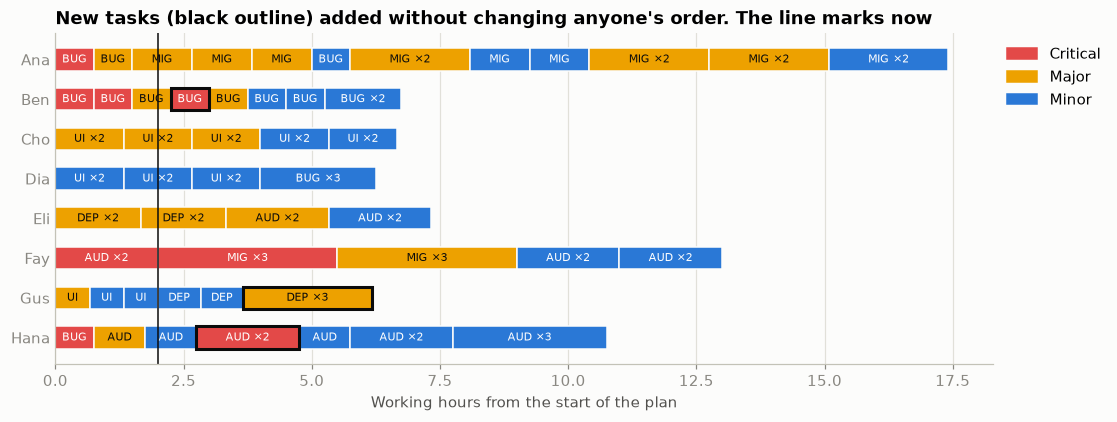

In [14]:
NOW = 120
gentle = results["Warm start, no search"].to_core()
ta.calculate_score(gentle)

was = {task.id: task.start_time for task in solved.tasks}
now = {task.id: task.start_time for task in gentle.tasks}
started = [task for task, start in was.items() if start < NOW]
delays = [now[task] - was[task] for task in was if was[task] >= NOW and now[task] > was[task]]
print(f"{sum(now[task] != was[task] for task in started)} of {len(started)} tasks already started were disturbed")
print(f"{len(delays)} tasks not yet started slide later, by up to {max(delays, default=0)} minutes")

fig, ax = plt.subplots(figsize=(11, 3.9))
draw_queues(ax, gentle, new_tasks=NEW)
ax.axvline(NOW / 60, color="#0b0b0b", linewidth=1)
ax.set_title("New tasks (black outline) added without changing anyone's order. The line marks now")
ax.legend(handles=PRIORITY_LEGEND, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

Construction picks the position, and nothing in this use case tells it which tasks are already running,
so check the first line above each time instead of assuming it. Keeping the order does not keep the
times: tasks behind a new one slide later. When that matters more than stability, spend search time
and accept that queues will change.

## Next steps

- `use-cases/task-assigning/README.md` covers the solver configuration and how to add your own moves and
  constraints in C++.
- For shifts on a calendar rather than a queue of work, see `employee-scheduling.ipynb`.